# Equivalent Gaussian width of each KBM field, from its GS2 extent

Fusion_PhD-qp5.49. The user's idea: read the 95 % extent of a GS2 eigenmode field as the 95 % interval of a Gaussian envelope, and so
turn it into the Hermite-basis WIDTH that field "wants". Each of the 738 GS2-KBMs then has a **width range**, one width per field, to
compare with the oracle width $W^*$, the TGLF search widths and the fixed WIDTH 0.4, and to set NBASIS.

**The conversion.** The extent $E$ (pyrokinetics `Extent`, 95 %) is the full $\theta$ interval holding 95 % of $\int\lvert f\rvert^2d\theta$,
2.5 % in each tail. The basis functions are $\psi_n(x)\propto H_n(x)e^{-x^2/2}$, $x=\theta/W$.
- $\phi$ (even, ballooning parity): $\lvert\psi_0\rvert^2\propto e^{-x^2}$ is a Gaussian of standard deviation $W/\sqrt2$, so
  $E_\phi=2z_{0.975}W/\sqrt2=2.772\,W$.
- $A_\parallel$ (odd): $\lvert\psi_1\rvert^2\propto x^2e^{-x^2}$, whose 95 % interval is $\lvert x\rvert<\sqrt{\chi^2_3(0.95)/2}=1.977$, so
  $E_{A_\parallel}=3.953\,W$.

**The coordinate.** The basis is not in $\theta$ but in the field-line arc length $\theta_b$, $x=\theta_b/{\rm WIDTH}$.
pyrokinetics maps $\theta\to\theta_b$ exactly from each sample's geometry (`FieldLine.compute_basis_angle`, pyro #617), so the factors
above are exact for an extent taken in $\theta_b$: $W_\phi=E^{\theta_b}_\phi/2.772$, $W_{A_\parallel}=E^{\theta_b}_{A_\parallel}/3.953$
(`Fusion_PhD-qp5.63`; the NBASIS-2 run calibration of qp5.49 is superseded). The oracle and NBASIS-convergence extents compare a code
with GS2 and stay in $\theta$.

In [1]:
import os
from math import comb
from multiprocessing import get_context
from pathlib import Path
import warnings
from dotenv import load_dotenv
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.ticker import NullLocator, StrMethodFormatter
from scipy.integrate import trapezoid
from scipy.stats import chi2, norm
from pyrokinetics import PyroHypercube
from pyrokinetics.diagnostics.extent import Extent
from pyrokinetics.diagnostics.field_line import FieldLine

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").is_file() and (path / "notebooks").is_dir())
plt.style.use(ROOT / "src/general_analysis/paper.mplstyle")
load_dotenv(ROOT / "local.env", override=True)
warnings.filterwarnings("ignore")
data_root = Path(os.path.expandvars(os.environ["GK_DATA_ROOT"]))     # the WORK tree
plots_dir = ROOT / "Plots" / "TGLF_GFTM_KBM_PAPER" / "equivalent_gaussian_width"
plots_dir.mkdir(parents=True, exist_ok=True)

cases = ["SPR-045", "M1", "R4", "R3"]
widths = [0.2, 0.2297, 0.2639, 0.3031, 0.3482, 0.4, 0.4595, 0.5279, 0.6063, 0.6965, 0.8, 0.9, 1.0, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6,
          1.9218, 2.3083, 2.7726, 3.3302, 4.0]
tglf_nbasis = [2, 4, 8, 16, 24]                                                       # fixed-width TGLF, FILTER -1.5, NXGRID 32
gftm_cells = {2: 32, 4: 32, 8: 32, 12: 32, 16: 32, 24: 32, 32: 40, 48: 65, 56: 64}     # fixed-width GFTM, FILTER 0.5, NBASIS: NXGRID
oracle_nbasis = [4, 8, 16, 24]
searches = {"SAT1": [(2, 4), (4, 8), (16, 16)], "SAT2": [(2, 4), (4, 8), (16, 16), (24, 24), (28, 28)], "SAT1, WIDTH_MIN 0.1": [(2, 4)]}
search_leaf = {"SAT1": "fw_f2p0_nb{a}-{b}", "SAT2": "s2_f2p0_nb{a}-{b}", "SAT1, WIDTH_MIN 0.1": "fw_f2p0_nb{a}-{b}_wmin0p1"}
fields = ["phi", "apar"]
field_label = {"phi": r"$\phi$", "apar": r"$A_\parallel$"}
grid_step = 1.15                 # the fixed widths are about 15 % apart: "inside the range within one grid step"
extent_tolerance = 0.10          # item 4: a field is converged at NBASIS N when its extent stays within 10 % of NBASIS 56 from N up
projection_tolerances = [0.10, 0.03, 0.01]   # item 4: relative L2 error of the Gaussian model's truncated expansion
n_cpu = int(os.environ.get("SLURM_CPUS_PER_TASK", 4))


def extent_95(squared_field):
    # pyro's 95 % extent rule, sample by sample (Extent._compute is the function Extent(output) calls); GS2's theta grid is
    # NaN outside each sample's own points, so NaNs are dropped first. A run with no output has an all-NaN field: NaN.
    return np.array([float(Extent._compute(row.dropna("theta").expand_dims("sample"), 0.95)[0][0]) if row.notnull().any() else np.nan
                     for row in squared_field.transpose("sample", "theta")])


def load(leaf):
    # gamma, omega, phi and A_par extents of the dominant mode, and the Gaussian width the run used, per sample
    scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    output = scan.gk_output.data.set_index(sample="sample_name")
    assert (output.growth_rate.pint.dequantify().fillna(-np.inf).argmax("mode") == 0).all()   # IBRANCH -1: mode 0 is dominant
    dominant = output.isel(mode=0)  # mode0-guard-allow: argmax == 0 asserted above
    return pd.DataFrame(dict(sample=[str(name) for name in output.sample.values],
                             gamma=dominant.growth_rate.pint.dequantify().values, omega=dominant.mode_frequency.pint.dequantify().values,
                             phi_extent=extent_95(abs(dominant.phi.pint.dequantify().squeeze("kx")) ** 2),
                             apar_extent=extent_95(abs(dominant.apar.pint.dequantify().squeeze("kx")) ** 2),
                             width=dominant.gaussian_width.pint.dequantify().values if "gaussian_width" in dominant else np.nan))

## The analytic factors

In [2]:
analytic_factor = {"phi": 2 * norm.ppf(0.975) / np.sqrt(2), "apar": 2 * np.sqrt(chi2.ppf(0.95, 3) / 2)}
x_check = np.linspace(-12, 12, 200001)
for field, density in (("phi", np.exp(-x_check ** 2)), ("apar", x_check ** 2 * np.exp(-x_check ** 2))):
    cumulative = np.cumsum(density) / density.sum()
    numerical = np.interp(0.975, cumulative, x_check) - np.interp(0.025, cumulative, x_check)
    assert abs(numerical - analytic_factor[field]) < 1e-3, (field, numerical)
print({field: round(factor, 3) for field, factor in analytic_factor.items()})

{'phi': np.float64(2.772), 'apar': np.float64(3.953)}


## Data and equivalent widths
GS2 extents of the 738 KBMs (the fixed-width leaves were built only for them, so their sample list is the population): in $\theta$, to
compare with the codes, and in $\theta_b$ (each sample's own geometry), which divided by the analytic factor is the equivalent width.
Then every fixed-width TGLF and GFTM leaf used below, and the TGLF search leaves.

In [3]:
gs2_rows = []
for case in cases:
    leaf = data_root / "GS2/Runs/LATIN_HYPERCUBE" / case / "kbm_free"
    gs2_scan = PyroHypercube(pyroscan_json=leaf / "pyroscan.json", load_base_pyro=True)
    gs2_scan.load_gk_output(netcdf_file=leaf / "pyroscan.nc")
    kbm_leaf = data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free/galF_w1p0000_nb16_nx32"
    population = [str(name) for name in PyroHypercube(pyroscan_json=kbm_leaf / "pyroscan.json", load_base_pyro=True).pyro_dict]
    gs2_output = gs2_scan.gk_output.data.set_index(sample="sample_name").sel(sample=population)
    rows = pd.DataFrame(dict(case=case, sample=population,
                             phi_extent_gs2=extent_95(gs2_output.phi_squared.pint.dequantify().squeeze("kx")),
                             apar_extent_gs2=extent_95(gs2_output.apar_squared.pint.dequantify().squeeze("kx"))))
    for i, name in enumerate(population):
        basis_angle = FieldLine(gs2_scan.sample_pyro(name, gk_output=xr.Dataset())).compute_basis_angle(gs2_output.theta.values)
        for field in fields:
            squared = gs2_output[f"{field}_squared"].sel(sample=[name]).pint.dequantify().squeeze("kx").assign_coords(theta=basis_angle)
            rows.loc[i, f"{field}_width"] = extent_95(squared)[0] / analytic_factor[field]
    gs2_rows.append(rows)
gs2 = pd.concat(gs2_rows, ignore_index=True)
assert len(gs2) == 738 and np.isfinite(gs2[["phi_width", "apar_width"]]).all().all()


def fixed_leaf(code, case, width, nbasis):
    width_tag = f"w{width:.4f}".replace(".", "p")
    if code == "TGLF":
        return data_root / "TGLF/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"fx_fm1p5_{width_tag}_nb{nbasis}"
    return data_root / "GFTM/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / f"galF_{width_tag}_nb{nbasis}_nx{gftm_cells[nbasis]}"


def load_fixed(spec):
    code, case, width, nbasis = spec
    return load(fixed_leaf(code, case, width, nbasis)).assign(code=code, case=case, fixed_width=width, nbasis=nbasis)


def load_search(spec):
    sat, case, (nb_min, nb_max) = spec
    leaf = data_root / "TGLF/Runs/LATIN_HYPERCUBE" / case / "kbm_free" / search_leaf[sat].format(a=nb_min, b=nb_max)
    return load(leaf).assign(sat=sat, case=case, search=f"{nb_min}-{nb_max}", nbasis=min(nb_max, 24))


fixed_specs = ([("TGLF", case, width, nbasis) for case in cases for width in widths for nbasis in tglf_nbasis]
               + [("GFTM", case, width, nbasis) for case in cases for width in widths for nbasis in gftm_cells])
search_specs = [(sat, case, nb) for sat in searches for case in cases for nb in searches[sat]]
with get_context("fork").Pool(n_cpu) as pool:
    fixed = pd.concat(pool.map(load_fixed, fixed_specs, chunksize=4), ignore_index=True).merge(gs2, on=["case", "sample"], validate="many_to_one")
    search = pd.concat(pool.map(load_search, search_specs), ignore_index=True).merge(gs2, on=["case", "sample"], validate="many_to_one")
print(fixed.groupby(["code", "nbasis"]).size().unstack(0))

code       GFTM     TGLF
nbasis                  
2       17712.0  17712.0
4       17712.0  17712.0
8       17712.0  17712.0
12      17712.0      NaN
16      17712.0  17712.0
24      17712.0  17712.0
32      17712.0      NaN
48      17712.0      NaN
56      17712.0      NaN


## Width range per KBM
$W_{\rm low}$, $W_{\rm high}$: the smaller and larger of $W_\phi$, $W_{A_\parallel}$. Per database: median, mean and 10-90 % range of each
width, and the middle of the central 90, 80 and 50 % of both fields' widths pooled, $(q_{05}+q_{95})/2$, $(q_{10}+q_{90})/2$, $(q_{25}+q_{75})/2$.

In [4]:
gs2["range_low"] = gs2[["phi_width", "apar_width"]].min(axis=1, skipna=False)
gs2["range_high"] = gs2[["phi_width", "apar_width"]].max(axis=1, skipna=False)
gs2["range_ratio"] = gs2.range_high / gs2.range_low
width_summary = pd.concat([gs2.assign(database=gs2.case), gs2.assign(database="pooled")]).groupby("database").agg(
    n=("sample", "size"),
    **{f"{field}_{statistic}": (f"{field}_width", aggregate) for field in fields
       for statistic, aggregate in (("median", "median"), ("q10", lambda width: width.quantile(0.1)), ("q90", lambda width: width.quantile(0.9)))},
    **{f"{field}_mean": (f"{field}_width", "mean") for field in fields},
    median_range_ratio=("range_ratio", "median"), median_range_low=("range_low", "median"), median_range_high=("range_high", "median"))
for database in width_summary.index:   # middle of the central 90, 80 and 50 % of phi and A_par widths pooled together
    rows = gs2 if database == "pooled" else gs2[gs2.case == database]
    for central, (lower, upper) in ((90, (0.05, 0.95)), (80, (0.10, 0.90)), (50, (0.25, 0.75))):
        low, high = rows[["phi_width", "apar_width"]].stack().quantile([lower, upper])
        width_summary.loc[database, [f"q{lower * 100:02.0f}_both", f"q{upper * 100:02.0f}_both", f"midrange_{central}"]] = low, high, (low + high) / 2
width_summary.to_csv(plots_dir / "equivalent_width_summary.csv")
print(width_summary.round(3).to_string())

            n  phi_median  phi_q10  phi_q90  apar_median  apar_q10  apar_q90  phi_mean  apar_mean  median_range_ratio  median_range_low  median_range_high  q05_both  q95_both  midrange_90  q10_both  q90_both  midrange_80  q25_both  q75_both  midrange_50
database                                                                                                                                                                                                                                                     
M1        140       0.808    0.583    1.943        0.521     0.328     0.764     1.098      0.574               1.548             0.521              0.808     0.311     2.099        1.205     0.432     1.438        0.935     0.515     0.894        0.704
R3        187       0.696    0.457    1.660        0.445     0.386     0.626     0.966      0.522               1.521             0.445              0.696     0.382     1.834        1.108     0.408     1.148        0.778     0.440     0.7

## Plots

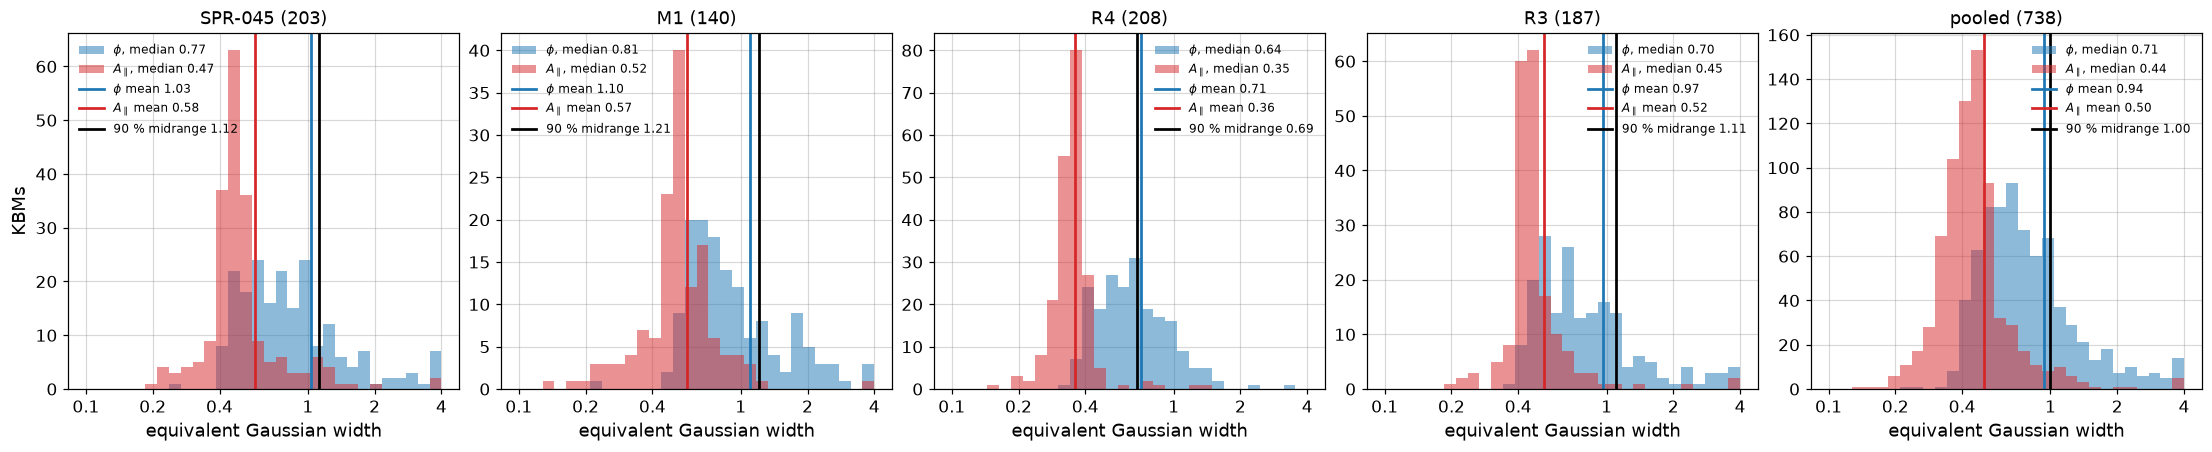

In [8]:
width_bins = np.geomspace(0.1, 4, 31)
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharex=True, constrained_layout=True)
for ax, database in zip(axes, cases + ["pooled"]):
    rows = gs2 if database == "pooled" else gs2[gs2.case == database]
    for field, colour in (("phi", "C0"), ("apar", "C3")):
        ax.hist(rows[f"{field}_width"].clip(0.101, 3.99), bins=width_bins, color=colour, alpha=0.5,
                label=f"{field_label[field]}, median {rows[f'{field}_width'].median():.2f}")
    for field, colour in (("phi", "C0"), ("apar", "C3")):
        mean = width_summary.loc[database, f"{field}_mean"]
        ax.axvline(mean, color=colour, marker="", label=f"{field_label[field]} mean {mean:.2f}")
    midrange = width_summary.loc[database, "midrange_90"]
    ax.axvline(midrange, color="k", marker="", label=f"90 % midrange {midrange:.2f}")
    ax.set_xscale("log"); ax.set_xticks([0.1, 0.2, 0.4, 1, 2, 4]); ax.xaxis.set_major_formatter(StrMethodFormatter("{x:g}")); ax.xaxis.set_minor_locator(NullLocator())
    ax.set(xlabel="equivalent Gaussian width", title=f"{database} ({len(rows)})")
    ax.legend(fontsize=8)
axes[0].set_ylabel("KBMs")
fig.savefig(plots_dir / "gs2_equivalent_width_histogram_per_database.pdf"); fig.savefig(plots_dir / "gs2_equivalent_width_histogram_per_database.png", dpi=150)
plt.show()

2. Oracle $W^*$ against the width range: the point is at $\sqrt{W_\phi W_{A_\parallel}}$, the bar spans $[W_{\rm low},W_{\rm high}]$ (ends outside the axes
   drawn at the edge). Dashed $y=x$.
3. The same for the TGLF search widths, one panel per search.